In [251]:
# ============================================================
# Global config
# ============================================================

import math
import random
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt

from scipy.signal import stft, resample_poly, find_peaks
from scipy.fft import rfft, irfft, rfftfreq
from scipy.ndimage import maximum_filter
import pyroomacoustics as pra

np.random.seed(42)
random.seed(42)
# ------------------------------------------------------------
# Acoustic / signal basics
# ------------------------------------------------------------
FS = 16000                 # sampling rate
C = 343.0                  # speed of sound [m/s]
DURATION_SEC = 3.0         # use same duration for all utterances


# ------------------------------------------------------------
# Input speech files
# ------------------------------------------------------------
LIBRISPEECH_FILES = [
    "C:/26'음향학회 춘계학술대회/male26.flac",
    # "C:/26'음향학회 춘계학술대회/male27.flac",
    "C:/26'음향학회 춘계학술대회/female19.flac",
    # "C:/26'음향학회 춘계학술대회/female32.flac",
    "C:/26'음향학회 춘계학술대회/female8975.flac",

]


# ------------------------------------------------------------
# Source configuration
# Standard spherical convention:
#   azimuth   : xy-plane from +x toward +y
#   elevation : from xy-plane toward +z
# ------------------------------------------------------------
# N_SOURCES = 5

# SOURCE_AZIMUTH_DEG = np.array([-30.0, -10.0,0.0,10.0,30.0], dtype=np.float64) #-35, 5, 40
# SOURCE_ELEVATION_DEG = np.array([0.0,0.0,0.0,0.0,0.0], dtype=np.float64)
# SOURCE_DISTANCES_M = np.array([3.4,3.2,3.0, 2.8,2.6], dtype=np.float64) #2.5, 2.8, 3.2

N_SOURCES = 3

SOURCE_AZIMUTH_DEG = np.array([-30.0,0.0,30.0], dtype=np.float64) #-35, 5, 40
SOURCE_ELEVATION_DEG = np.array([-10.0,0.0,10.0], dtype=np.float64)
SOURCE_DISTANCES_M = np.array([3.2,3.0,2.8], dtype=np.float64) #2.5, 2.8, 3.2

ARRAY_CENTER = np.array([0.0, 0.0, 1.5], dtype=np.float64)


# ------------------------------------------------------------
# Array comparison setting
#
# same_spacing:
#   linear adjacent spacing = tetra edge length = BASE_VALUE_M
#
# same_baseline:
#   linear max baseline = tetra max baseline = BASE_VALUE_M
#   -> linear spacing = BASE_VALUE_M / 3
#   -> tetra edge     = BASE_VALUE_M
# ------------------------------------------------------------
COMPARE_MODE = "same_spacing"   # "same_spacing" or "same_baseline"
BASE_VALUE_M = 0.29            # 8 cm


# ------------------------------------------------------------
# Frequency selection
# Recommended: use fixed frequency first for stable comparison
# ------------------------------------------------------------
USE_FIXED_CENTER_HZ = False
FIXED_CENTER_HZ = 1100.0

SEARCH_FMIN_HZ = 300.0
SEARCH_FMAX_HZ = 3400.0
BANDWIDTH_HZ = 150.0


# ------------------------------------------------------------
# STFT
# ------------------------------------------------------------
STFT_NFFT = 1024
STFT_HOP = 256


# ------------------------------------------------------------
# MUSIC scan grids
# Linear: azimuth-only 1D scan
# Tetra : azimuth + elevation 2D scan
# ------------------------------------------------------------
AZ_GRID_DEG = np.linspace(-90.0, 90.0, 1801)     # 0.1 deg resolution
EL_GRID_DEG = np.linspace(-60.0, 60.0, 121)      # 1 deg resolution


# ------------------------------------------------------------
# Optional plotting / debug
# ------------------------------------------------------------
PLOT_RAW_AND_BAND_SPECTRA = True
PLOT_MIC_SIGNALS = True
PLOT_LINEAR_MUSIC = True
PLOT_TETRA_MUSIC = True


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------
assert len(LIBRISPEECH_FILES) == N_SOURCES, \
    f"Number of files ({len(LIBRISPEECH_FILES)}) must match N_SOURCES ({N_SOURCES})"

assert len(SOURCE_AZIMUTH_DEG) == N_SOURCES
assert len(SOURCE_ELEVATION_DEG) == N_SOURCES
assert len(SOURCE_DISTANCES_M) == N_SOURCES

print("Global config loaded.")
print(f"N_SOURCES           : {N_SOURCES}")
print(f"COMPARE_MODE        : {COMPARE_MODE}")
print(f"BASE_VALUE_M        : {BASE_VALUE_M:.4f} m")
print(f"USE_FIXED_CENTER_HZ : {USE_FIXED_CENTER_HZ}")
if USE_FIXED_CENTER_HZ:
    print(f"FIXED_CENTER_HZ     : {FIXED_CENTER_HZ:.1f} Hz")

Global config loaded.
N_SOURCES           : 3
COMPARE_MODE        : same_spacing
BASE_VALUE_M        : 0.2900 m
USE_FIXED_CENTER_HZ : False


In [252]:
# ============================================================
# Common helpers
# ============================================================

# ------------------------------------------------------------
# Audio helpers
# ------------------------------------------------------------
def read_audio_mono_resample(path: str, target_fs: int) -> np.ndarray:
    x, fs = sf.read(path)

    if x.ndim > 1:
        x = np.mean(x, axis=1)

    x = x.astype(np.float64)

    if fs != target_fs:
        print('sampling rate unmatched resampling...')
        g = math.gcd(fs, target_fs)
        up = target_fs // g
        down = fs // g
        x = resample_poly(x, up, down)

    x = x - np.mean(x)
    x = x / (np.max(np.abs(x)) + 1e-12)
    return x


def center_crop_or_pad(x: np.ndarray, target_len: int) -> np.ndarray:
    if len(x) >= target_len:
        start = (len(x) - target_len) // 2
        return x[start:start + target_len].copy()

    print("audio shorter than target, zero padding...")
    y = np.zeros(target_len, dtype=np.float64)
    y[:len(x)] = x
    return y


def average_speech_spectrum(x: np.ndarray, fs: int, n_fft: int = 2048, hop: int = 512) -> tuple[np.ndarray, np.ndarray]:
    f, _, Z = stft(x, fs=fs, window="hann", nperseg=n_fft, noverlap=n_fft - hop, boundary=None, padded=False)

    mag = np.abs(Z)
    frame_energy = np.mean(mag**2, axis=0)

    thr = np.percentile(frame_energy, 10.0)
    valid = frame_energy > thr
    if not np.any(valid):
        print('error: no energy bigger than threshold')
        valid = np.ones_like(frame_energy, dtype=bool)

    avg_mag = np.mean(mag[:, valid], axis=1)
    return f, avg_mag


def choose_common_dominant_band(signals: list[np.ndarray], fs: int, fmin_hz: float, fmax_hz: float,) -> float:
    stacked = None
    freqs = None

    for x in signals:
        f, avg_mag = average_speech_spectrum(x, fs=fs)
        avg_mag = avg_mag / (np.max(avg_mag) + 1e-12)

        if stacked is None:
            stacked = avg_mag
            freqs = f
        else:
            stacked += avg_mag

    mask = (freqs >= fmin_hz) & (freqs <= fmax_hz)
    if not np.any(mask):
        raise ValueError("No FFT bins inside search range.")

    f_sel = freqs[mask]
    a_sel = stacked[mask]
    center_hz = f_sel[np.argmax(a_sel)]
    return float(center_hz)


def get_center_frequency(signals: list[np.ndarray]) -> float:
    if USE_FIXED_CENTER_HZ:
        return float(FIXED_CENTER_HZ)

    return choose_common_dominant_band(
        signals=signals,
        fs=FS,
        fmin_hz=SEARCH_FMIN_HZ,
        fmax_hz=SEARCH_FMAX_HZ,
    )


def fft_keep_only_band(x: np.ndarray, fs: int, center_hz: float, bandwidth_hz: float) -> np.ndarray:
    n = len(x)
    X = rfft(x)
    f = rfftfreq(n, d=1.0 / fs)

    half_bw = bandwidth_hz / 2.0
    mask = (f >= center_hz - half_bw) & (f <= center_hz + half_bw)

    Y = np.zeros_like(X)
    Y[mask] = X[mask]
    y = irfft(Y, n=n)

    y = y - np.mean(y)
    y = y / (np.max(np.abs(y)) + 1e-12)
    return y.astype(np.float64)


def prepare_narrowband_sources(file_paths: list[str], duration_sec: float) -> tuple[list[np.ndarray], list[np.ndarray], float]:
    target_len = int(FS * duration_sec)

    raw_sources = []
    for path in file_paths:
        x = read_audio_mono_resample(path, FS)
        x = center_crop_or_pad(x, target_len)
        raw_sources.append(x)

    center_hz = get_center_frequency(raw_sources)

    narrow_sources = [
        fft_keep_only_band(
            x,
            fs=FS,
            center_hz=center_hz,
            bandwidth_hz=BANDWIDTH_HZ,
        )
        for x in raw_sources
    ]

    return raw_sources, narrow_sources, center_hz


# ------------------------------------------------------------
# Common geometry / source helpers
# ------------------------------------------------------------
def sph_to_cart(
    center_xyz: np.ndarray,
    az_deg: float,
    el_deg: float,
    r: float,
) -> np.ndarray:
    az = np.deg2rad(az_deg)
    el = np.deg2rad(el_deg)

    x = center_xyz[0] + r * np.cos(el) * np.cos(az)
    y = center_xyz[1] + r * np.cos(el) * np.sin(az)
    z = center_xyz[2] + r * np.sin(el)

    return np.array([x, y, z], dtype=np.float64)


def build_source_positions() -> list[np.ndarray]:
    positions = []
    for az_deg, el_deg, dist_m in zip(
        SOURCE_AZIMUTH_DEG,
        SOURCE_ELEVATION_DEG,
        SOURCE_DISTANCES_M,
    ):
        positions.append(
            sph_to_cart(
                center_xyz=ARRAY_CENTER,
                az_deg=az_deg,
                el_deg=el_deg,
                r=dist_m,
            )
        )
    return positions

def true_linear_broadside_deg(
    source_positions: list[np.ndarray],
    array_center: np.ndarray,
) -> np.ndarray:
    """
    x-axis ULA 기준 true broadside angle 계산
    0 deg  : +y (broadside)
    - angle: +x 쪽으로 기울어짐
    + angle: -x 쪽으로 기울어짐
    """
    angles = []
    for p in source_positions:
        rel = np.asarray(p, dtype=np.float64) - np.asarray(array_center, dtype=np.float64)
        dx, dy = rel[0], rel[1]
        theta_deg = np.rad2deg(np.arctan2(-dx, dy))
        angles.append(theta_deg)
    return np.array(angles, dtype=np.float64)


# ------------------------------------------------------------
# Common STFT / covariance helpers
# ------------------------------------------------------------
def multichannel_stft(
    y_mics: np.ndarray,
    fs: int,
    n_fft: int,
    hop: int,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    Z_all = []
    f_ref = None
    t_ref = None

    for m in range(y_mics.shape[0]):
        f, t, Z = stft(
            y_mics[m],  
            fs=fs,
            window="hann",
            nperseg=n_fft,
            noverlap=n_fft - hop,
            boundary=None,
            padded=False,
        )
        Z_all.append(Z)

        if f_ref is None:
            f_ref = f
            t_ref = t

    Z_all = np.stack(Z_all, axis=0)  # M x F x T
    return f_ref, t_ref, Z_all


def extract_frequency_bin_snapshots(
    y_mics: np.ndarray,
    fs: int,
    target_hz: float,
    n_fft: int,
    hop: int,
) -> tuple[float, np.ndarray]:
    f, _, Z = multichannel_stft(y_mics, fs, n_fft=n_fft, hop=hop)
    k = int(np.argmin(np.abs(f - target_hz)))
    print('shape after stft', Z.shape)
    print('target center_hz', target_hz)
    print('calculated center_hz', f[k])
    X_bin = Z[:, k, :]  # M x N_snapshots
    return float(f[k]), X_bin


def sample_covariance(X: np.ndarray) -> np.ndarray:
    return (X @ X.conj().T) / X.shape[1]


# ------------------------------------------------------------
# Common simulation / metric helpers
# ------------------------------------------------------------
def simulate_array_signals(
    mic_locs: np.ndarray,
    source_positions: list[np.ndarray],
    source_signals: list[np.ndarray],
    fs: int,
) -> np.ndarray:
    room = pra.AnechoicRoom(fs=fs, dim=3)
    room.add_microphone_array(mic_locs)

    for pos, sig in zip(source_positions, source_signals):
        room.add_source(pos, signal=sig)
    snr_db=0
    room.simulate(snr=snr_db)
    return room.mic_array.signals


def azimuth_rmse_deg(
    true_az_deg: np.ndarray,
    est_az_deg: np.ndarray,
) -> float:
    true_az = np.sort(np.asarray(true_az_deg, dtype=np.float64))
    est_az = np.sort(np.asarray(est_az_deg, dtype=np.float64))

    if len(true_az) != len(est_az):
        raise ValueError(
            f"RMSE source count mismatch: true={len(true_az)}, est={len(est_az)}"
        )

    return float(np.sqrt(np.mean((est_az - true_az) ** 2)))




# ============================================================
# Linear array helpers
# ============================================================

# ------------------------------------------------------------
# Linear array helpers
# ------------------------------------------------------------
def get_linear_spacing_from_config() -> float:
    """
    same_spacing:
        linear adjacent spacing = BASE_VALUE_M

    same_baseline:
        linear max baseline = BASE_VALUE_M
        -> adjacent spacing = BASE_VALUE_M / 3
    """
    if COMPARE_MODE == "same_spacing":
        return float(BASE_VALUE_M)

    if COMPARE_MODE == "same_baseline":
        return float(BASE_VALUE_M / 3.0)

    raise ValueError("COMPARE_MODE must be 'same_spacing' or 'same_baseline'")


def make_linear_ula(
    center_xyz: np.ndarray,
    spacing_m: float,
) -> np.ndarray:
    """
    4-mic uniform linear array on y-axis.
    Returns shape (3, 4)
    """
    offsets = np.array([0,1,2,3,4,5], dtype=np.float64) * spacing_m
    offsets = offsets - np.mean(offsets)
    # offsets = np.array([-0.435, -0.145, 0.145, 0.435], dtype=np.float64)

    x = np.full(6, center_xyz[0], dtype=np.float64)
    y = center_xyz[1] + offsets
    z = np.full(6, center_xyz[2], dtype=np.float64)

    return np.vstack([x, y, z])


def build_linear_array() -> tuple[np.ndarray, float]:
    spacing_m = get_linear_spacing_from_config()
    mic_locs = make_linear_ula(
        center_xyz=ARRAY_CENTER,
        spacing_m=spacing_m,
    )
    return mic_locs, spacing_m

# ------------------------------------------------------------
# Linear azimuth-only MUSIC
# ------------------------------------------------------------

def steering_vector_linear_azimuth(
    mic_positions_xyz: np.ndarray,
    array_center_xyz: np.ndarray,
    freq_hz: float,
    az_deg: float,
    c: float = 343.0,
) -> np.ndarray:
    """
    Linear ULA azimuth-only steering vector.
    Elevation is assumed to be 0 deg.
    """
    az = np.deg2rad(az_deg)
    y_rel = mic_positions_xyz[1, :] - array_center_xyz[1]
    phase = 2.0j * np.pi * freq_hz / c * y_rel * np.sin(az)
    return np.exp(phase)[:, None]


def music_spectrum_linear_1d(
    R: np.ndarray,
    mic_positions_xyz: np.ndarray,
    array_center_xyz: np.ndarray,
    freq_hz: float,
    n_sources: int,
    az_grid_deg: np.ndarray,
    c: float = 343.0,
) -> np.ndarray:
    eigvals, eigvecs = np.linalg.eigh(R)
    order = np.argsort(eigvals)[::-1]
    eigvecs = eigvecs[:, order]

    En = eigvecs[:, n_sources:]
    P = np.zeros(len(az_grid_deg), dtype=np.float64)

    for i, az in enumerate(az_grid_deg):
        a = steering_vector_linear_azimuth(
            mic_positions_xyz=mic_positions_xyz,
            array_center_xyz=array_center_xyz,
            freq_hz=freq_hz,
            az_deg=az,
            c=c,
        )
        denom = (a.conj().T @ En @ En.conj().T @ a).squeeze()
        P[i] = 1.0 / (np.abs(denom) + 1e-12)

    P = P / (np.max(P) + 1e-12)
    return P

def estimate_music_peaks_1d(
    P: np.ndarray,
    az_grid_deg: np.ndarray,
    n_sources: int,
    min_peak_distance_deg: float = 5.0,
) -> list[tuple[float, float]]:
    step_deg = float(np.abs(az_grid_deg[1] - az_grid_deg[0]))
    min_distance_bins = max(1, int(min_peak_distance_deg / step_deg))

    peaks, _ = find_peaks(P, distance=min_distance_bins)
    if len(peaks) == 0:
        return []

    peak_vals = P[peaks]
    order = np.argsort(peak_vals)[::-1]
    chosen = peaks[order[:n_sources]]

    results = [(float(az_grid_deg[i]), float(P[i])) for i in chosen]
    results.sort(key=lambda x: x[0])
    return results

def run_linear_music_pipeline(
    mic_locs: np.ndarray,
    source_positions: list[np.ndarray],
    source_signals: list[np.ndarray],
    center_hz: float,
) -> dict:
    y_mics = simulate_array_signals(
        mic_locs=mic_locs,
        source_positions=source_positions,
        source_signals=source_signals,
        fs=FS,
    )

    chosen_bin_hz, X_bin = extract_frequency_bin_snapshots(
        y_mics=y_mics,
        fs=FS,
        target_hz=center_hz,
        n_fft=STFT_NFFT,
        hop=STFT_HOP,
    )
    print('X_bin shape:', X_bin.shape)

    R = sample_covariance(X_bin)
    print('covariance shape:', R.shape)

    P = music_spectrum_linear_1d(
        R=R,
        mic_positions_xyz=mic_locs,
        array_center_xyz=ARRAY_CENTER,
        freq_hz=chosen_bin_hz,
        n_sources=N_SOURCES,
        az_grid_deg=AZ_GRID_DEG,
        c=C,
    )
    
    peaks = estimate_music_peaks_1d(
        P=P,
        az_grid_deg=AZ_GRID_DEG,
        n_sources=N_SOURCES,
    )
    print('estimated peaks:',peaks)

    est_az_deg = np.array([p[0] for p in peaks], dtype=np.float64)

    return {
        "array_name": "Linear ULA (4 mics)",
        "mic_locs": mic_locs,
        "y_mics": y_mics,
        "chosen_bin_hz": chosen_bin_hz,
        "X_bin": X_bin,
        "R": R,
        "P": P,
        "peaks": peaks,
        "est_az_deg": est_az_deg,
    }

def plot_linear_music_1d(
    result: dict,
    true_az_deg: np.ndarray,
):
    P = result["P"]

    plt.figure(figsize=(10, 4))
    plt.plot(
        AZ_GRID_DEG,
        10.0 * np.log10(P + 1e-12),
        label="Linear MUSIC",
    )

    for az in true_az_deg:
        plt.axvline(az, linestyle="--")

    for az, _ in result["peaks"]:
        plt.axvline(az, linestyle=":")

    plt.xlabel("Azimuth (deg)")
    plt.ylabel("Normalized spectrum (dB)")
    plt.title(f"{result['array_name']} MUSIC spectrum at {result['chosen_bin_hz']:.2f} Hz")
    plt.xlim(AZ_GRID_DEG[0], AZ_GRID_DEG[-1])
    plt.tight_layout()
    plt.show()

true source size: (48000,)
true source size: (48000,)
center frequency Hz: 578.125
[array([ 2.7291793 , -1.5756924 ,  0.94432583]), array([3. , 0. , 1.5]), array([2.38803189, 1.37873085, 1.9862149 ])]
[[ 0.     0.     0.     0.     0.     0.   ]
 [-0.725 -0.435 -0.145  0.145  0.435  0.725]
 [ 1.5    1.5    1.5    1.5    1.5    1.5  ]]
shape after stft (6, 513, 185)
target center_hz 578.125
calculated center_hz 578.125
X_bin shape: (6, 185)
covariance shape: (6, 6)
estimated peaks: [(-28.299999999999997, 0.8140923786190069), (0.10000000000000853, 0.9999999999997845), (28.10000000000001, 0.5784142153116487)]
center_hz: 578.125
linear spacing: 0.29
estimated azimuths: [-28.3   0.1  28.1]
azimuth RMSE: 1.473091986265621


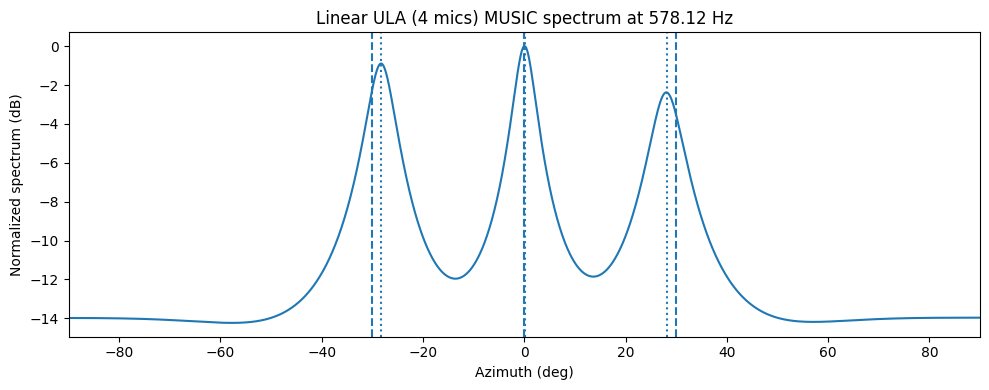

In [253]:
raw_sources, narrow_sources, center_hz = prepare_narrowband_sources(
    LIBRISPEECH_FILES,
    DURATION_SEC,
)
print('true source size:', raw_sources[0].shape) #(3, 48000)
print('true source size:', narrow_sources[0].shape) #(3, 48000)
print('center frequency Hz:', center_hz) #1800Hz

source_positions = build_source_positions() #(3,3)
print(source_positions)

linear_mics, linear_spacing = build_linear_array() #(4,3), 2.667
print(linear_mics)
linear_result = run_linear_music_pipeline(
    mic_locs=linear_mics,
    source_positions=source_positions,
    source_signals=narrow_sources,
    center_hz=center_hz,
)

print("center_hz:", center_hz)
print("linear spacing:", linear_spacing)
print("estimated azimuths:", linear_result["est_az_deg"])
try:
    rmse_val = azimuth_rmse_deg(SOURCE_AZIMUTH_DEG, linear_result["est_az_deg"])
    print("azimuth RMSE:", rmse_val)
except ValueError as e:
    print(f"azimuth RMSE: 계산 불가 ({e})")

plot_linear_music_1d(linear_result, SOURCE_AZIMUTH_DEG)

Target center frequency: 578.12 Hz
True source size: (48000,)
True Azimuths (deg): [-30.   0.  30.]
Physical Array Spacing: 0.2900 m

--- Starting HEN-MUSIC Pipeline ---
shape after stft (4, 513, 185)
target center_hz 578.125
calculated center_hz 578.125
mic y positions: [-0.6525 -0.3625  0.2175  0.7975]
lag keys: [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5]
Running HEN Matrix Completion on 6x6 virtual array...
HEN Completion converged at iteration 2

Array Info         : HEN MUSIC (Virtual 6 mics)
Estimated Azimuths : [-29.6   0.   29.6]
Peaks (Angle, Mag) : [(-29.599999999999994, 0.9999999999999234), (0.0, 0.26737689874621556), (29.60000000000001, 0.9999999999999221)]
Azimuth RMSE       : 0.3266 deg



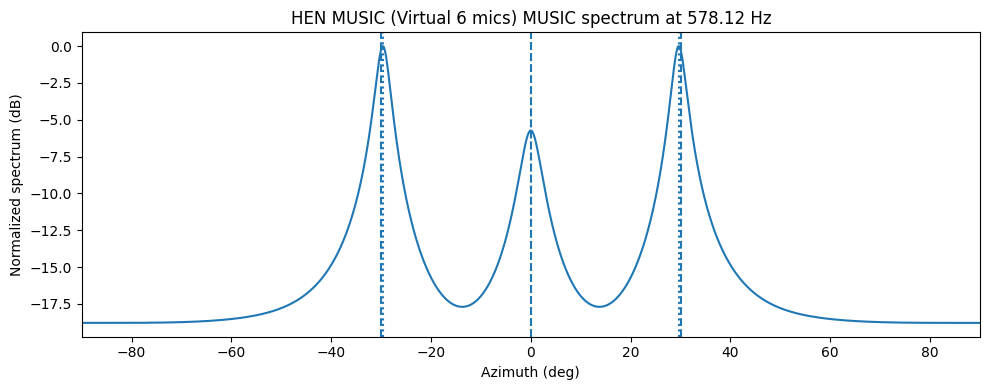

In [254]:
import numpy as np
from scipy.optimize import minimize_scalar
from scipy.linalg import toeplitz, eigh

# ============================================================
# 1. HEN (Hyperbolic Exponential Norm) 수학 모듈
# ============================================================
def h_val(x: float, a: float, p: float) -> float:
    """논문 Eq (15): 쌍곡선 지수 노름 함수"""
    exp_xp = np.exp(x**p)
    return a * (exp_xp - 1.0) / (exp_xp + 1.0)

def prox_h(y: float, lam: float, a: float, p: float) -> float:
    """논문 Lemma 1 / Eq (20-22): h(x)에 대한 근접 연산자(Proximal Operator)"""
    if y <= 0.0:
        return 0.0

    def obj(x):
        return lam * h_val(x, a, p) + 0.5 * (x - y)**2

    # 수치적 최적화를 통해 [0, y] 구간 내에서 최소값을 탐색
    res = minimize_scalar(obj, bounds=(0, y), method='bounded')
    x_hat = res.x

    # 0일 때와 최적화된 x_hat일 때의 목적함수 값 비교
    if obj(x_hat) < obj(0.0):
        return x_hat
    return 0.0

# ============================================================
# 2. HEN 행렬 복원 알고리즘 (Algorithm 1)
# ============================================================
def hen_matrix_completion(R_hat: np.ndarray, G: np.ndarray, a: float = 100.0, p: float = 1.05, rho: float = 1.0, eta: float = 1e-3, max_iter: int = 500, tol: float = 1e-8) -> np.ndarray:
    L_dim = R_hat.shape[0]
    H = R_hat.copy().astype(np.complex128)
    L_mat = R_hat.copy().astype(np.complex128)

    lam = 1.0 / (rho + eta)
    ones_minus_G = np.ones((L_dim, L_dim), dtype=np.float64) - G

    for it in range(max_iter):
        H_prev = H.copy()

        # Eq. (30)
        temp_H = (rho * L_mat + eta * H) / (rho + eta)
        H = R_hat + temp_H * ones_minus_G

        # Hermitian 보정
        H = 0.5 * (H + H.conj().T)

        # Eq. (32), (33)
        Y = (rho * H + eta * L_mat) / (rho + eta)
        Y = 0.5 * (Y + Y.conj().T)

        U, S, Vh = np.linalg.svd(Y, full_matrices=False)
        S_new = np.array([prox_h(float(s), lam, a, p) for s in S], dtype=np.float64)
        L_mat = U @ np.diag(S_new) @ Vh

        # Hermitian 보정
        L_mat = 0.5 * (L_mat + L_mat.conj().T)

        diff_norm = np.linalg.norm(H - H_prev, 'fro')
        prev_norm = np.linalg.norm(H_prev, 'fro') + 1e-12
        if diff_norm / prev_norm <= tol:
            print(f"HEN Completion converged at iteration {it+1}")
            break

    H = 0.5 * (H + H.conj().T)
    return H

# ============================================================
# 3. 주파수 종속형 가상 배열(Virtual Co-array) 생성기
# ============================================================
def build_virtual_toeplitz_and_G_dynamic(
    R: np.ndarray,
    mic_locs_y: np.ndarray,
    center_hz: float,
    c: float = 343.0
):
    M = R.shape[0]

    lam = c / center_hz
    d = lam / 2.0

    lag_dict = {}

    for i in range(M):
        for j in range(M):
            dist = mic_locs_y[i] - mic_locs_y[j]
            lag = int(np.round(dist / d))   # 논문식이면 애초에 정수 grid가 더 바람직
            lag_dict.setdefault(lag, []).append(R[i, j])

    min_lag = min(lag_dict.keys())
    max_lag = max(lag_dict.keys())

    # 논문 Eq. (10): U = <min(D), max(D)>
    all_lags = np.arange(min_lag, max_lag + 1)

    r_full = np.zeros(len(all_lags), dtype=np.complex128)
    g_full = np.zeros(len(all_lags), dtype=np.float64)

    for idx, lag in enumerate(all_lags):
        if lag in lag_dict:
            r_full[idx] = np.mean(lag_dict[lag])
            g_full[idx] = 1.0

    # 중심 lag=0 index
    zero_idx = -min_lag

    # Toeplitz 만들기 위한 first column / first row
    # column: lag 0, +1, +2, ...
    r_col = r_full[zero_idx:]
    g_col = g_full[zero_idx:]

    # row: lag 0, -1, -2, ...
    r_row = r_full[zero_idx::-1].conj()
    g_row = g_full[zero_idx::-1]

    R_hat = toeplitz(r_col, r_row)
    G = toeplitz(g_col, g_row)

    # 논문 예시와 같은 L 개념: Toeplitz 크기
    L = R_hat.shape[0]
    print("mic y positions:", mic_locs_y)
    print("lag keys:", sorted(lag_dict.keys()))

    return R_hat, G, L, d

# ============================================================
# 4. HEN-MUSIC 통합 파이프라인
# ============================================================
def run_hen_music_pipeline(
    mic_locs: np.ndarray,
    source_positions: list[np.ndarray],
    source_signals: list[np.ndarray],
    center_hz: float
) -> dict:
    
    # 1. 신호 시뮬레이션 및 기존 STFT -> 공분산 R 추출
    y_mics = simulate_array_signals(mic_locs, source_positions, source_signals, FS) # snr_db 옵션을 껐다면 여기서 제거
    chosen_bin_hz, X_bin = extract_frequency_bin_snapshots(y_mics, FS, center_hz, STFT_NFFT, STFT_HOP)
    R_physical = sample_covariance(X_bin)

    # 2. 주파수 기반 가상 배열 생성 및 마스크 추출
    mic_locs_y = mic_locs[1, :]
    R_hat, G, L_virtual, virtual_spacing_m = build_virtual_toeplitz_and_G_dynamic(
        R_physical, mic_locs_y, chosen_bin_hz, C
    )
    
    # 3. HEN Matrix Completion
    print(f"Running HEN Matrix Completion on {L_virtual}x{L_virtual} virtual array...")
    H_completed = hen_matrix_completion(R_hat, G)
    H_completed = 0.5 * (H_completed + H_completed.conj().T)
    
    # 4. Completed 행렬을 이용한 MUSIC 스펙트럼 계산
    eigvals, eigvecs = eigh(H_completed)
    order = np.argsort(eigvals)[::-1]
    eigvecs = eigvecs[:, order]
    
    Un = eigvecs[:, N_SOURCES:]
    P = np.zeros(len(AZ_GRID_DEG), dtype=np.float64)
    
    for i, az_deg in enumerate(AZ_GRID_DEG):
        az = np.deg2rad(az_deg)
        # 가상 반파장 간격을 적용한 조향 벡터 생성
        virtual_y_rel = np.arange(L_virtual) * virtual_spacing_m
        phase = 2.0j * np.pi * chosen_bin_hz / C * virtual_y_rel * np.sin(az)
        a_vec = np.exp(phase)[:, None]
        
        denom = (a_vec.conj().T @ Un @ Un.conj().T @ a_vec).squeeze()
        P[i] = 1.0 / (np.abs(denom) + 1e-12)

    P = P / (np.max(P) + 1e-12)
    peaks = estimate_music_peaks_1d(P, AZ_GRID_DEG, N_SOURCES)
    est_az_deg = np.array([p[0] for p in peaks], dtype=np.float64)

    return {
        "array_name": f"HEN MUSIC (Virtual {L_virtual} mics)",
        "chosen_bin_hz": chosen_bin_hz,
        "P": P,
        "peaks": peaks,
        "est_az_deg": est_az_deg,
    }

# ============================================================
# 5. Main Execution Block (메인 실행부)
# ============================================================
def build_linear_array() -> tuple[np.ndarray, float]:
    spacing_m = 0.29  # 29cm
    
    # 0, 1, 4, 7 위치에 마이크를 듬성듬성 배치 (Sparse Array)
    grid = np.array([0,1,3,5], dtype=np.float64) * spacing_m
    offsets = grid - np.mean(grid)
    # offsets = np.array([-0.435, -0.20, 0.10, 0.435], dtype=np.float64)

    # 배열의 무게중심을 맞추기 위해 중앙으로 이동
    offsets = offsets - np.mean(offsets)

    x = np.full(4, ARRAY_CENTER[0], dtype=np.float64)
    y = ARRAY_CENTER[1] + offsets
    z = np.full(4, ARRAY_CENTER[2], dtype=np.float64)

    mic_locs = np.vstack([x, y, z])
    return mic_locs, spacing_m

# 1. 협대역 음원 신호 준비 (Librispeech 파일 로드 및 필터링)
raw_sources, narrow_sources, center_hz = prepare_narrowband_sources(
    LIBRISPEECH_FILES,
    DURATION_SEC,
)
print(f"Target center frequency: {center_hz:.2f} Hz") 
print(f"True source size: {raw_sources[0].shape}")

# 2. 3D 공간 상의 음원 위치 설정 및 정답 방위각 로드
source_positions = build_source_positions()
true_broadside_deg = SOURCE_AZIMUTH_DEG # 수정된 방식: 설정값을 그대로 정답으로 사용
print("True Azimuths (deg):", true_broadside_deg)

# 3. 물리적 마이크 배열 생성 (Y축 일렬 배치)
linear_mics, linear_spacing = build_linear_array() 
print(f"Physical Array Spacing: {linear_spacing:.4f} m")

# 4. 🔥 HEN-MUSIC 파이프라인 실행 🔥
print("\n--- Starting HEN-MUSIC Pipeline ---")
hen_result = run_hen_music_pipeline(
    mic_locs=linear_mics,
    source_positions=source_positions,
    source_signals=narrow_sources,
    center_hz=center_hz,
)

# 5. 결과 출력
print("\n========================================")
print("Array Info         :", hen_result["array_name"])
print("Estimated Azimuths :", hen_result["est_az_deg"])
print("Peaks (Angle, Mag) :", hen_result["peaks"])

# 에러가 나더라도 프로그램이 뻗지 않고 스펙트럼 그래프를 볼 수 있도록 처리
try:
    rmse_val = azimuth_rmse_deg(true_broadside_deg, hen_result["est_az_deg"])
    print(f"Azimuth RMSE       : {rmse_val:.4f} deg")
except ValueError as e:
    print(f"Azimuth RMSE       : 계산 불가 ({e})")
print("========================================\n")

# 6. 공간 스펙트럼(Spatial Spectrum) 그래프 시각화
plot_linear_music_1d(hen_result, true_broadside_deg)

Target center frequency: 1100.00 Hz
True Azimuths (deg): [-30.   0.  30.]
Physical Array Spacing: 0.1500 m


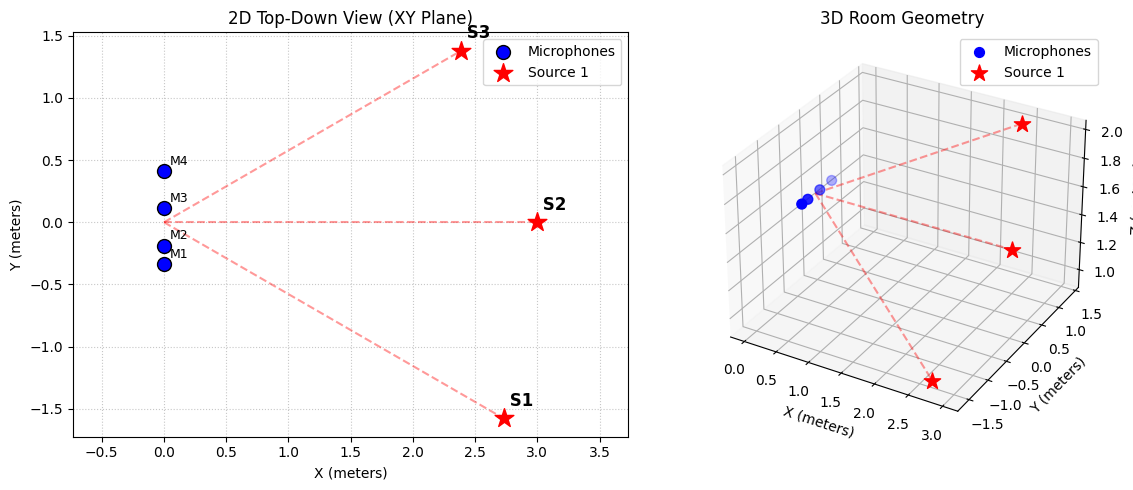

In [250]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def plot_room_geometry(mic_locs: np.ndarray, source_positions: list[np.ndarray]):
    """
    마이크 배열과 음원의 위치를 2D Top-down 뷰와 3D 뷰로 시각화합니다.
    """
    fig = plt.figure(figsize=(12, 5))

    # 배열 중심점 계산
    center_x = np.mean(mic_locs[0, :])
    center_y = np.mean(mic_locs[1, :])
    center_z = np.mean(mic_locs[2, :])

    # ==========================================
    # 1. 2D Top-Down View (XY 평면)
    # 방위각(Azimuth)을 확인하기 가장 좋은 뷰입니다.
    # ==========================================
    ax1 = fig.add_subplot(121)
    
    # 마이크 위치 (파란색 동그라미)
    ax1.scatter(mic_locs[0, :], mic_locs[1, :], c='blue', s=100, label='Microphones', edgecolors='k', zorder=3)
    
    # 음원 위치 (빨간색 별) 및 연결선
    for i, pos in enumerate(source_positions):
        ax1.scatter(pos[0], pos[1], c='red', marker='*', s=200, label=f'Source {i+1}' if i==0 else "", zorder=3)
        # 중심에서 음원까지의 시선(Line of sight)
        ax1.plot([center_x, pos[0]], [center_y, pos[1]], 'r--', alpha=0.4)
        ax1.text(pos[0], pos[1] + 0.1, f' S{i+1}', fontsize=12, fontweight='bold')

    for i in range(mic_locs.shape[1]):
        ax1.text(mic_locs[0, i] + 0.05, mic_locs[1, i] + 0.05, f'M{i+1}', fontsize=9)

    ax1.set_xlabel("X (meters)")
    ax1.set_ylabel("Y (meters)")
    ax1.set_title("2D Top-Down View (XY Plane)")
    ax1.grid(True, linestyle=':', alpha=0.7)
    ax1.axis('equal') # X, Y 비율을 똑같이 맞춰야 각도가 왜곡되지 않습니다.
    ax1.legend()

    # ==========================================
    # 2. 3D View
    # 전체적인 공간 배치를 입체적으로 확인합니다.
    # ==========================================
    ax2 = fig.add_subplot(122, projection='3d')
    
    # 마이크 위치
    ax2.scatter(mic_locs[0, :], mic_locs[1, :], mic_locs[2, :], c='blue', s=50, label='Microphones', depthshade=True)
    
    # 음원 위치
    for i, pos in enumerate(source_positions):
        ax2.scatter(pos[0], pos[1], pos[2], c='red', marker='*', s=150, label=f'Source {i+1}' if i==0 else "")
        ax2.plot([center_x, pos[0]], [center_y, pos[1]], [center_z, pos[2]], 'r--', alpha=0.4)

    ax2.set_xlabel("X (meters)")
    ax2.set_ylabel("Y (meters)")
    ax2.set_zlabel("Z (meters)")
    ax2.set_title("3D Room Geometry")
    ax2.legend()

    plt.tight_layout()
    plt.show()

raw_sources, narrow_sources, center_hz = prepare_narrowband_sources(
    LIBRISPEECH_FILES,
    DURATION_SEC,
)
print(f"Target center frequency: {center_hz:.2f} Hz") 

# 2. 3D 공간 상의 음원 위치 설정 및 정답 방위각 로드
source_positions = build_source_positions()
true_broadside_deg = SOURCE_AZIMUTH_DEG # 수정된 방식: 설정값을 그대로 정답으로 사용
print("True Azimuths (deg):", true_broadside_deg)

# 3. 물리적 마이크 배열 생성 (Y축 일렬 배치)
linear_mics, linear_spacing = build_linear_array() 
print(f"Physical Array Spacing: {linear_spacing:.4f} m")

plot_room_geometry(linear_mics, source_positions)